# stabilizer-qec

**What it is.** A QEC simulator and decoder library written in Rust with Python bindings, by Jasper Sands
(PyPI: `stabilizer-qec` 2.1.0, https://qcompiler.jaspersands.com). It is very large: it re-implements Stim's
circuit language, PyMatching, `ldpc`'s decoders, Relay-BP, Ambiguity Clustering, lattice surgery and more.
We use **only the pip package**, not the GitHub repo.

**What we use it for.** Its gross code object: check matrices, logical operators, automorphisms, the
Bravyi et al. memory circuit (our cross-check of IBM's circuit), the gauging logical-measurement circuit (used
in our test of IBM's independence assumption), and its decoders, which run locally.

| Step | What we do | Graph |
|---|---|---|
| 1 | Install, what is inside | contents by kind |
| 2 | The gross code object | check matrices, logical operator weights |
| 3 | Automorphisms (the symmetries Tour de gross uses for logic) | how many logical qubits each one moves |
| 4 | Memory circuit: look inside | operations per time step |
| 5 | Logical measurement circuit (gauging) | size vs memory circuit |
| 6 | Decoders on the same shots: BP-OSD, BP-LSD, Relay-BP, Ambiguity Clustering | failures and time |
| 7 | Is its Relay-BP the same as IBM's? | agreement |
| 8 | What we take from it | – |


## Setup

Run once in a fresh environment (Python 3.12 recommended). The versions are the ones the results were produced with.

In [ ]:
%pip install -q stim==1.16.0 sinter==1.15.0 stabilizer-qec==2.1.0 "numpy>=2.0,<2.3" pandas matplotlib
# Optional: IBM's own Relay-BP decoder. No ready-made Windows wheel: building it needs the Rust compiler
# (https://rustup.rs). Without it, stabilizer-qec's RelayBp (same algorithm) is used where possible.
# %pip install -q "relay-bp[stim]"

### Code and data used from this folder

Functions that several notebooks share are kept in `helpers/` rather than repeated in every notebook; they are
imported from there below. Each file is commented and can be read on its own.

| File | What it is for | Used here |
|---|---|---|
| `helpers/tour_helpers.py` | plotting, tables, running and caching experiments | `cached_run`, `count_failures`, `relay_installed`, `savefig`, `show_head`, `wilson` |

Folders read or written:
- `results/`: cached runs (re-used, not re-run)
- `figures/`: PNG files written by this notebook

## Step 1 · Install, and what is inside

    pip install stabilizer-qec==2.1.0

The chart sorts the package's public names into rough kinds by their names.

stabilizer-qec 2.1.0 · A quantum error-correction simulator and decoder in Rust: circuits and error models in Stim's formats, exact sparse-blossom, correlated and belief matching, BP+ ...


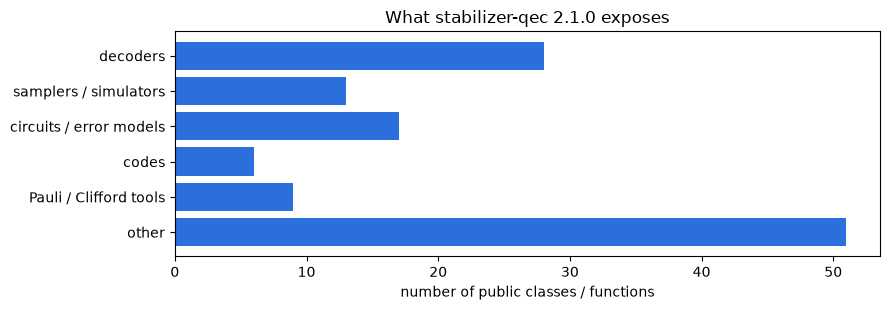

decoders: ['AmbiguityClustering', 'BeliefFindDecoder', 'BeliefMatching', 'BpDecoder', 'BpFlipDecoder', 'BpLsd', 'BpLsdDecoder', 'BpOsd', 'BpOsdDecoder', 'CollisionClustering', 'ColorMatching', 'CompositeDecoder', 'LeakageAwareDecoder', 'LocalClustering', 'LsdDecoder', 'Matching', 'MbpDecoder', 'PreDecoder', 'RelayBp', 'RelayBpDecoder', 'SearchDecoder', 'SoftInfoBpDecoder', 'SoftInfoBpOsdDecoder', 'SubgraphDecoder', 'UnionFind', 'UnionFindDecoder', 'Window', 'WindowMatching']


In [2]:
import sys, time; sys.path.insert(0, "helpers")   # helper functions (see "Code and data used" above)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, stim
import stabilizer_qec as sq
import tour_helpers as tour
import importlib.metadata as md
print("stabilizer-qec", md.version("stabilizer-qec"), "·", md.metadata("stabilizer-qec")["Summary"][:160], "...")

names = [x for x in dir(sq) if not x.startswith("_")]
kinds = {"decoders": ("Decoder", "Bp", "Matching", "Clustering", "UnionFind", "Relay", "Lsd", "Osd", "Window"),
         "samplers / simulators": ("Sampler", "Simulator"),
         "circuits / error models": ("Circuit", "Dem", "Gate", "Flow", "Diagram"),
         "codes": ("Code", "Automorphism", "Gauging", "surgery", "memory_circuit"),
         "Pauli / Clifford tools": ("Pauli", "Tableau", "Clifford", "clifford")}
counts = {k: sorted({n for n in names if any(s in n for s in v)}) for k, v in kinds.items()}
counts["other"] = sorted(set(names) - set().union(*counts.values()))
plt.figure(figsize=(9, 3.2))
plt.barh(list(counts), [len(v) for v in counts.values()], color="#2a6fdb")
plt.xlabel("number of public classes / functions"); plt.title("What stabilizer-qec 2.1.0 exposes")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()
print("decoders:", counts["decoders"])

## Step 2 · The gross code object

`BivariateBicycleCode("gross")` is the [[144,12,12]] code of Bravyi et al.: 144 data qubits, 12 logical qubits,
distance 12, defined by two polynomials on a 12 × 6 torus.

polynomials (l, m, A, B): (12, 6, [(3, 0), (0, 1), (0, 2)], [(0, 3), (1, 0), (2, 0)])
n = 144   k = 12
H_X: (72, 144)  checks per qubit: {np.uint64(3)}  qubits per check: {np.uint64(6)}


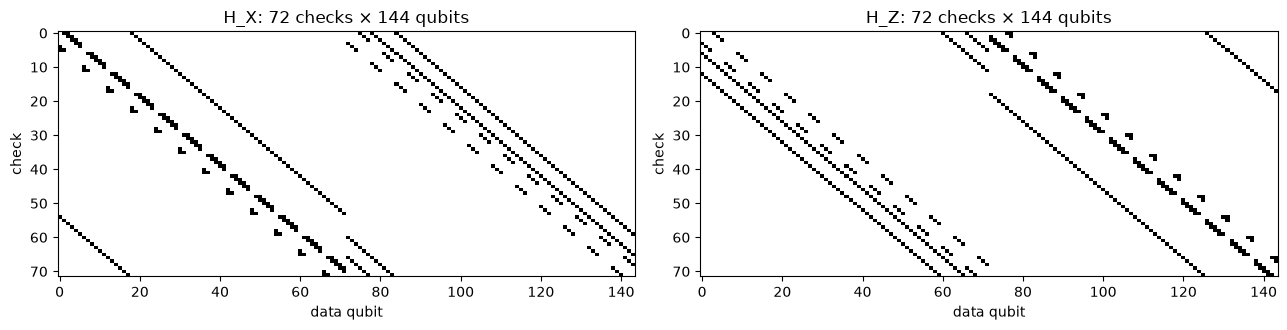

In [3]:
gross = sq.BivariateBicycleCode("gross")
print("polynomials (l, m, A, B):", gross.polynomials)
print("n =", gross.n, "  k =", gross.k)
HX, HZ = gross.check_matrices()
print("H_X:", HX.shape, " checks per qubit:", set(np.asarray(HX).sum(axis=0)), " qubits per check:", set(np.asarray(HX).sum(axis=1)))

fig, axs = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, H, t in [(axs[0], HX, "H_X"), (axs[1], HZ, "H_Z")]:
    ax.imshow(np.asarray(H), cmap="Greys", aspect="auto", interpolation="nearest")
    ax.set_title(f"{t}: 72 checks × 144 qubits"); ax.set_xlabel("data qubit"); ax.set_ylabel("check")
plt.tight_layout(); tour.savefig("sq_gross_check_matrices.png"); plt.show()

Every check touches 6 qubits and every qubit is in 3 X and 3 Z checks: that is what makes the code
**LDPC** (low-density parity check). The 12 logical operators, from `gross.logicals()`:

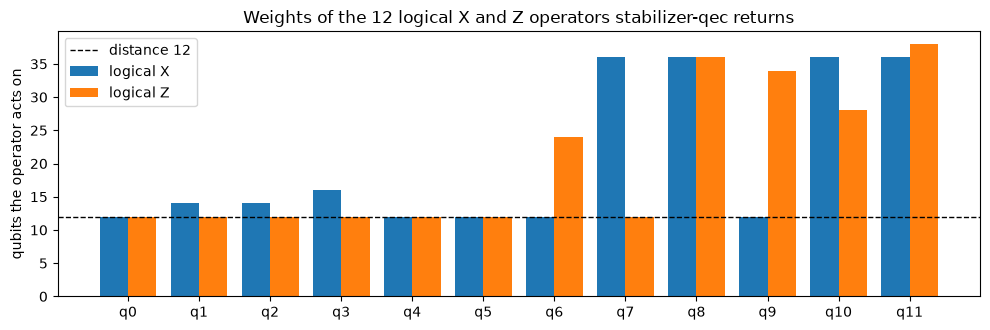

X weights: [12, 14, 14, 16, 12, 12, 12, 36, 36, 12, 36, 36]
Z weights: [12, 12, 12, 12, 12, 12, 24, 12, 36, 34, 28, 38]


In [4]:
LX, LZ = gross.logicals()
wX, wZ = np.asarray(LX).sum(axis=1), np.asarray(LZ).sum(axis=1)
x = np.arange(12)
plt.figure(figsize=(10, 3.4))
plt.bar(x - 0.2, wX, 0.4, label="logical X"); plt.bar(x + 0.2, wZ, 0.4, label="logical Z")
plt.axhline(12, color="k", ls="--", lw=1, label="distance 12")
plt.xticks(x, [f"q{i}" for i in x]); plt.ylabel("qubits the operator acts on")
plt.title("Weights of the 12 logical X and Z operators stabilizer-qec returns"); plt.legend()
plt.tight_layout(); tour.savefig("sq_logical_weights.png"); plt.show()
print("X weights:", wX.tolist()); print("Z weights:", wZ.tolist())

**Where each logical operator sits.** Each row below is one logical X operator; a black cell means it acts on
that data qubit. The right panel counts, for each qubit, how many of the 12 logical X operators use it. Many
qubits are shared by several logical qubits, which is why a gate on a few physical qubits cannot touch just one
logical qubit.

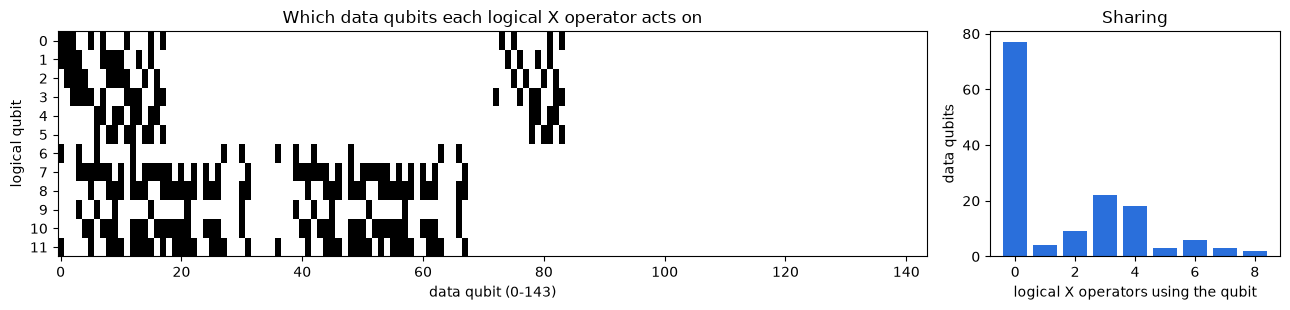

data qubits used by 2 or more logical X operators: 63 of 144


In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={"width_ratios": [3, 1]})
a1.imshow(np.asarray(LX), cmap="Greys", aspect="auto", interpolation="nearest")
a1.set_xlabel("data qubit (0-143)"); a1.set_ylabel("logical qubit"); a1.set_yticks(range(12))
a1.set_title("Which data qubits each logical X operator acts on")
shared = np.asarray(LX).sum(axis=0)
a2.bar(*np.unique(shared, return_counts=True), color="#2a6fdb")
a2.set_xlabel("logical X operators using the qubit"); a2.set_ylabel("data qubits"); a2.set_title("Sharing")
plt.tight_layout(); tour.savefig("sq_logical_supports.png"); plt.show()
print("data qubits used by 2 or more logical X operators:", int((shared >= 2).sum()), "of 144")

None is lighter than 12, the code distance. The heavier ones (24–38) are a valid but not minimal choice; any
logical operator can be multiplied by checks without changing what it does.

## Step 3 · Automorphisms

An automorphism is a relabelling of the 144 qubits that maps the code to itself. The gross code has 144:
72 shifts of the 12 × 6 torus, each with or without swapping X and Z ("dual"). Tour de gross
(Yoder et al., arXiv:2506.03094) uses the shifts as cheap logical gates: they move logical information between
the 12 logical qubits without touching it. stabilizer-qec gives each one's **action** on the logical qubits as a
24 × 24 binary matrix (12 X parts, 12 Z parts).

144 automorphisms; example: shift (0, 0) dual True


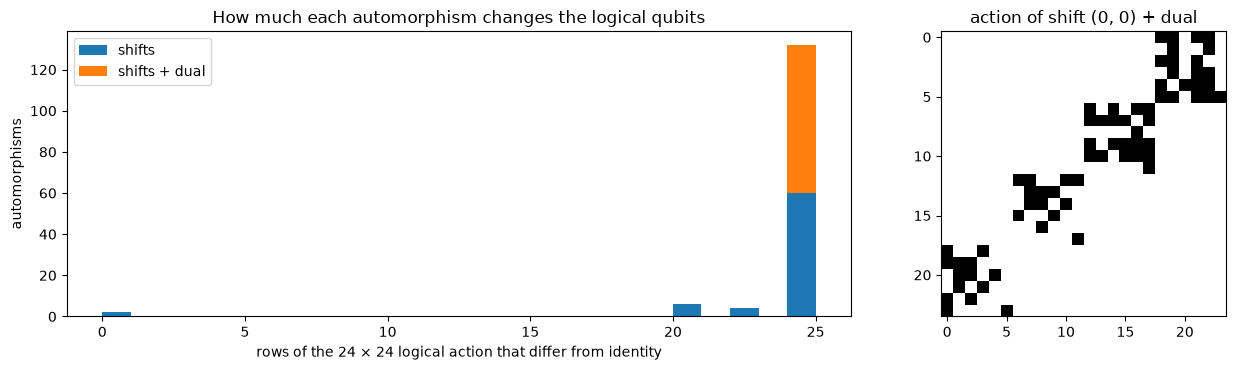

In [6]:
autos = gross.automorphisms()
print(len(autos), "automorphisms; example:", "shift", autos[1].shift, "dual", autos[1].dual)
moved = [int((np.asarray(a.action) != np.eye(24, dtype=int)).any(axis=1).sum()) for a in autos]
df = pd.DataFrame({"shift": [str(a.shift) for a in autos], "dual": [a.dual for a in autos], "rows_changed": moved})

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2, 1]})
a1.hist([df[~df.dual].rows_changed, df[df.dual].rows_changed], bins=range(0, 26), label=["shifts", "shifts + dual"], stacked=True)
a1.set_xlabel("rows of the 24 × 24 logical action that differ from identity"); a1.set_ylabel("automorphisms")
a1.set_title("How much each automorphism changes the logical qubits"); a1.legend()
a2.imshow(np.asarray(autos[1].action), cmap="Greys")
a2.set_title(f"action of shift {autos[1].shift}" + (" + dual" if autos[1].dual else ""))
plt.tight_layout(); tour.savefig("sq_automorphisms.png"); plt.show()

Two of the 144 automorphisms (both plain shifts, one of them the identity) leave every logical qubit
unchanged; the other 142 act as non-trivial logical operations.
**What stabilizer-qec does not give** is a noisy *circuit* for a shift, so we cannot yet simulate its error rate.

## Step 4 · The memory circuit

`gross.memory_circuit(rounds, p)` writes the Bravyi et al. syndrome cycle as a Stim circuit with uniform
circuit noise p. This is the circuit we used as the cross-check of IBM's (notebook 02).

In [7]:
P = 0.004
mem = stim.Circuit(str(gross.memory_circuit(12, P)))
print(f"qubits: {mem.num_qubits}   detectors: {mem.num_detectors}   logical observables: {mem.num_observables}")
tour.show_head(mem, 8, start="CX")

qubits: 288   detectors: 936   logical observables: 12
... (lines 1-295 skipped)
CX 198 216 199 217 200 218 201 219 202 220 203 221 204 222 205 223 206 224 207 225 208 226 209 227 210 228 211 229 212 230 213 231 214 232 2 ...
DEPOLARIZE2(0.004) 198 216 199 217 200 218 201 219 202 220 203 221 204 222 205 223 206 224 207 225 208 226 209 227 210 228 211 229 212 230 2 ...
DEPOLARIZE1(0.004) 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 96 97 98 99 100 101 102 103 104 105 106 107 108 1 ...
TICK
CX 0 73 1 74 2 75 3 76 4 77 5 72 6 79 7 80 8 81 9 82 10 83 11 78 12 85 13 86 14 87 15 88 16 89 17 84 18 91 19 92 20 93 21 94 22 95 23 90 24  ...
DEPOLARIZE2(0.004) 0 73 1 74 2 75 3 76 4 77 5 72 6 79 7 80 8 81 9 82 10 83 11 78 12 85 13 86 14 87 15 88 16 89 17 84 18 91 19 92 20 93 21 94 ...
TICK
CX 0 150 1 151 2 152 3 153 4 154 5 155 6 156 7 157 8 158 9 159 10 160 11 161 12 162 13 163 14 164 15 165 16 166 17 167 18 168 19 169 20 170  ...
... (1639 lines in total)


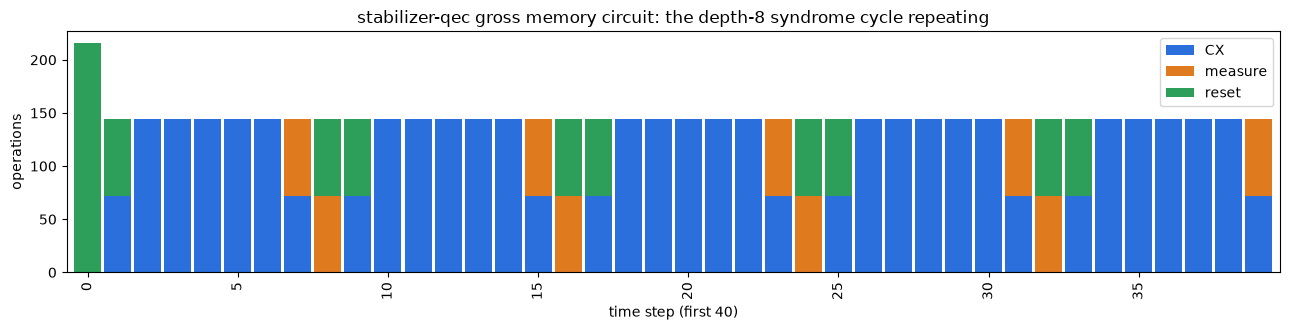

In [8]:
def per_tick(c):
    ops, cur = [], {"CX": 0, "measure": 0, "reset": 0}
    for inst in c.flattened():
        n = len(inst.targets_copy())
        if inst.name == "TICK": ops.append(cur); cur = {"CX": 0, "measure": 0, "reset": 0}
        elif inst.name == "CX": cur["CX"] += n // 2
        elif inst.name in ("M", "MX"): cur["measure"] += n
        elif inst.name in ("R", "RX"): cur["reset"] += n
    return pd.DataFrame(ops + [cur])
t = per_tick(mem)
ax = t.iloc[:40].plot.bar(stacked=True, figsize=(13, 3.4), width=0.9, color=["#2a6fdb", "#e07a1f", "#2e9e5b"])
ax.set_xlabel("time step (first 40)"); ax.set_ylabel("operations"); ax.set_xticks(range(0, 40, 5), range(0, 40, 5))
ax.set_title("stabilizer-qec gross memory circuit: the depth-8 syndrome cycle repeating")
plt.tight_layout(); tour.savefig("sq_memory_timeline.png"); plt.show()

The pattern repeats every 8 time steps — the depth-8 syndrome cycle. In each step about 144 operations run
in parallel: mostly CX gates, with the measurements and resets of the 144 check qubits overlapping the first
and last CX layers of each round. 12 rounds = about 100 time steps.

## Step 5 · The logical measurement circuit (gauging)

`gross.logical_measurement_circuit(op, basis, pre, merged, post, p)` measures one logical operator by "gauging"
(Williamson & Yoder, arXiv:2410.02213; Cross, He, Rall & Yoder, arXiv:2407.18393): extra qubits are joined to
the code for `merged` rounds so the product of their checks reveals the logical value. This circuit was used
in our test of IBM's independence assumption.

,"memory, 14 rounds",1 + measure(12) + 1
qubits,288,325
detectors,1080,1212
observables,12,13
error mechanisms,10224,11165


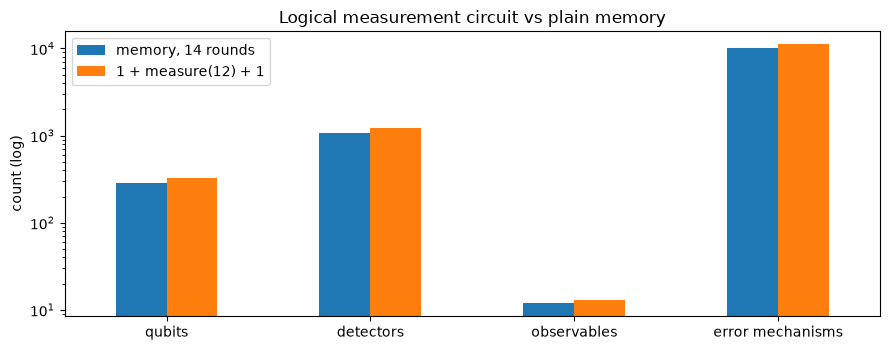

In [9]:
meas = stim.Circuit(str(gross.logical_measurement_circuit("f", "x", pre=1, merged=12, post=1, p=P)))
memx = stim.Circuit(str(gross.memory_circuit(14, P, basis="x")))     # same total length, no measurement
cmp = pd.DataFrame({
    "memory, 14 rounds": [memx.num_qubits, memx.num_detectors, memx.num_observables,
                          memx.detector_error_model(decompose_errors=False).num_errors],
    "1 + measure(12) + 1": [meas.num_qubits, meas.num_detectors, meas.num_observables,
                            meas.detector_error_model(decompose_errors=False).num_errors]},
    index=["qubits", "detectors", "observables", "error mechanisms"])
display(cmp)
cmp.plot.bar(logy=True, rot=0, figsize=(9, 3.6)); plt.title("Logical measurement circuit vs plain memory")
plt.ylabel("count (log)"); plt.tight_layout(); tour.savefig("sq_measurement_vs_memory.png"); plt.show()

The measurement adds qubits, detectors and one extra observable (the measured value) — and many more ways
to fail, which is why it is one of the "instructions" in Tour de gross's error budget.

## Step 6 · Four decoders on the same shots

The gross memory circuit at p = 0.005, 300 shots sampled once and given to every decoder. All four run
locally, in stabilizer-qec:

| Decoder | Idea | Paper |
|---|---|---|
| **BP-OSD** | BP; if it fails, solve the check equations by linear algebra, trying alternatives (order 10) | Roffe et al., arXiv:2005.07016 |
| **BP-LSD** | the same, but on small separate clusters around the flagged checks, so it can run in parallel | Hillmann et al., arXiv:2406.18655 |
| **Relay-BP** | BP run several times in a chain, each with a "memory" of the last; no linear algebra, so suited to chips | Müller et al., arXiv:2506.01779 |
| **Ambiguity Clustering** | BP, then split into independent blocks and only resolve the ambiguous ones | Wolanski & Barber, arXiv:2406.14527 |

Settings: BP-OSD as IBM's (min-sum, 80 iterations, OSD-CS order 10); the others at the package defaults
(which copy each original library's defaults).

,circuit,p,decoder,shots,failures,seconds,same_prediction,fail_ibm,fail_sq,P_L
0,gross memory 12 rounds,0.005,BP-OSD,300,49.0,19.5,NaN,NaN,NaN,0.163333
1,gross memory 12 rounds,0.005,BP-LSD,300,91.0,27.1,NaN,NaN,NaN,0.303333
2,gross memory 12 rounds,0.005,Relay-BP,300,31.0,139.6,NaN,NaN,NaN,0.103333
3,gross memory 12 rounds,0.005,Ambiguity Clustering,300,26.0,4.6,NaN,NaN,NaN,0.086667


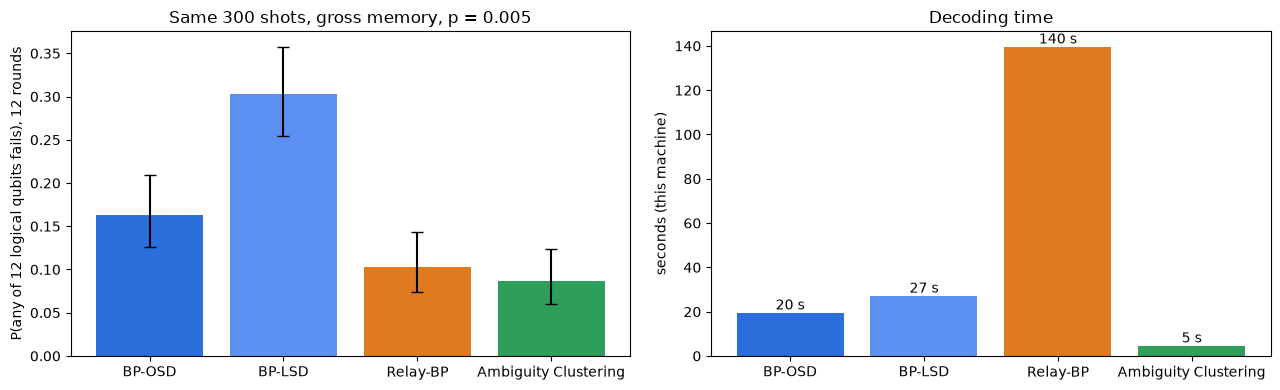

In [10]:
DP, SHOTS = 0.005, 300
circ = stim.Circuit(str(gross.memory_circuit(12, DP)))
dem = circ.detector_error_model(decompose_errors=False)
dets, obs = circ.compile_detector_sampler(seed=5).sample(SHOTS, separate_observables=True)

DECODERS = {
    "BP-OSD":               lambda: sq.BpOsd(dem, max_iter=80, bp_method="minimum_sum", osd_method="osd_cs", osd_order=10),
    "BP-LSD":               lambda: sq.BpLsd(dem),
    "Relay-BP":             lambda: sq.RelayBp(dem),
    "Ambiguity Clustering": lambda: sq.AmbiguityClustering(dem),
}
rows = []
for name, make in DECODERS.items():
    r = tour.cached_run("results/sq_decoders.csv", {"circuit": "gross memory 12 rounds", "p": DP, "decoder": name},
                        lambda make=make: (lambda t, d: {"shots": SHOTS, "failures": tour.count_failures(d.decode_batch(dets), obs),
                                                         "seconds": round(time.time() - t, 1)})(time.time(), make()))
    rows.append(r)
res = pd.DataFrame(rows); res["P_L"] = res.failures / res.shots
display(res)
ci = np.array([tour.wilson(f, n) for f, n in zip(res.failures, res.shots)])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
cols = ["#2a6fdb", "#5b8ff0", "#e07a1f", "#2e9e5b"]
a1.bar(res.decoder, res.P_L, color=cols); a1.errorbar(range(len(res)), res.P_L, yerr=[res.P_L - ci[:, 0], ci[:, 1] - res.P_L], fmt="none", color="k", capsize=4)
a1.set_ylabel("P(any of 12 logical qubits fails), 12 rounds"); a1.set_title(f"Same {SHOTS} shots, gross memory, p = {DP}")
a2.bar(res.decoder, res.seconds, color=cols)
for i, s in enumerate(res.seconds): a2.text(i, s, f"{s:.0f} s", ha="center", va="bottom")
a2.set_ylabel("seconds (this machine)"); a2.set_title("Decoding time")
plt.tight_layout(); tour.savefig("sq_four_decoders.png"); plt.show()

**What it shows (our run, 300 shots).** Ambiguity Clustering 8.7% and Relay-BP 10.3% failed fewer shots
than BP-OSD 16.3%, in line with IBM's published finding that Relay-BP beats BP-OSD on the gross code.
BP-LSD failed most often (30%). We also tried it with BP-OSD-like settings (80 iterations, order-10 search) on the
same shots and got the same (94 failures), so this is not just its defaults; we have not tuned it or checked
it against `ldpc`'s own BP-LSD yet. Timing: AC fastest (~5 s), Relay-BP slowest (~140 s). 300 shots gives wide
error bars (see the black lines), so treat the ranking as a first look. A larger comparison (on the surface code,
with 20,000 shots per point) is in `surface_code_decoders/`.

## Step 7 · Is stabilizer-qec's Relay-BP the same as IBM's?

stabilizer-qec's documentation says its Relay-BP gives the same corrections as IBM's `relay_bp`. Check: decode
the same shots with both (IBM's through its Sinter decoder) and count how often their predictions agree. This
cell needs IBM's `relay_bp` package; without it, the saved result is shown.

In [11]:
def compare_relay(n=100):
    if not tour.relay_installed():
        return None
    from relay_bp.stim import sinter_decoders
    ibm = sinter_decoders()["relay-bp"].compile_decoder_for_dem(dem=dem)
    d = dets[:n]
    packed = np.packbits(d, axis=1, bitorder="little")
    p_ibm = np.unpackbits(ibm.decode_shots_bit_packed(bit_packed_detection_event_data=packed),
                          axis=1, bitorder="little")[:, :dem.num_observables].astype(bool)
    p_sq = np.asarray(sq.RelayBp(dem).decode_batch(d), bool)
    return {"shots": n, "same_prediction": int((p_ibm == p_sq).all(axis=1).sum()),
            "fail_ibm": tour.count_failures(p_ibm, obs[:n]), "fail_sq": tour.count_failures(p_sq, obs[:n])}
r = tour.cached_run("results/sq_decoders.csv", {"circuit": "relay equivalence", "p": DP, "decoder": "IBM vs stabilizer-qec"}, compare_relay)
print(r if r else "IBM relay_bp not installed and no saved result")

{'circuit': 'relay equivalence', 'p': 0.005, 'decoder': 'IBM vs stabilizer-qec', 'shots': 100, 'failures': nan, 'seconds': nan, 'same_prediction': 93.0, 'fail_ibm': 10.0, 'fail_sq': 11.0}


**Result.** On 100 shots, IBM's `relay_bp` and stabilizer-qec's `RelayBp` gave the same prediction on 93
and different ones on 7; they failed 10 and 11 times. So they are close but **not identical shot for shot**
(likely different random draws of the memory strengths, which the method uses), and their failure rates are
the same within noise. For results we report, IBM's own `relay_bp` is the reference.

## Step 8 · What we take from stabilizer-qec

| From stabilizer-qec | Where we use it |
|---|---|
| `BivariateBicycleCode("gross")`: check matrices, logicals, automorphisms | cross-checks in notebook 03 and `codes_from_polynomials/` |
| `memory_circuit` | cross-check of IBM's circuit (notebook 02) |
| `logical_measurement_circuit` | our test of IBM's independence assumption |
| BP-OSD, BP-LSD, Relay-BP, Ambiguity Clustering | fast local decoders; the comparison in `surface_code_decoders/` |

**Sources:** stabilizer-qec 2.1.0 (PyPI) · Bravyi et al., *Nature* 627, 778 (2024) · Yoder et al.,
arXiv:2506.03094 (Tour de gross) · Williamson & Yoder, arXiv:2410.02213 · Cross, He, Rall & Yoder,
arXiv:2407.18393 · Roffe et al., arXiv:2005.07016 · Hillmann et al., arXiv:2406.18655 · Müller et al.,
arXiv:2506.01779 · Wolanski & Barber, arXiv:2406.14527.